# Cvičení: Detekce anomálií studentů pomocí Isolation Forest

**Cíle cvičení:**
1. Načíst dataset `student_scores.csv` (30 641 studentů).
2. Ponechat pouze tři klíčové číselné atributy: `MathScore`, `ReadingScore` a `WritingScore`.
3. Provést redukci dimenzionality na 2 dimenze pomocí **PCA** pro přehlednou vizualizaci.
4. Natrénovat model `IsolationForest` za předpokladu, že anomálie tvoří **2.5 %** všech pozorování (`contamination=0.025`).
5. Vygenerovat grafické znázornění detekovaných anomálií a běžných studentů.
6. Otestovat a graficky porovnat chování modelu při snížení kontaminace na **1.0 %** (`contamination=0.01`).
7. Analyzovat akademické profily detekovaných anomálií (extrémní selhání vs. silná asymetrie schopností).

In [1]:
# Import potřebných knihoven
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

# Nastavení vizualizačního stylu
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Knihovny úspěšně importovány.')

Knihovny úspěšně importovány.


## 1. Načtení datasetu student_scores.csv a výběr sloupců

Dataset načteme pomocí kandidátních cest podporujících lokální běh i Google Colab.

In [2]:
# Robustní načtení dat
data_candidates = [
    Path('../data/Downloadable materials for Session 3/student_scores.csv'),
    Path('data/Downloadable materials for Session 3/student_scores.csv'),
    Path('../data/student_scores.csv'),
    Path('data/student_scores.csv'),
    Path('student_scores.csv')
]

csv_path = None
for cand in data_candidates:
    if cand.exists():
        csv_path = cand
        break

if csv_path is None:
    raise FileNotFoundError('Soubor student_scores.csv nebyl nalezen.')

df_raw = pd.read_csv(csv_path)
print(f'Dataset úspěšně načten z: {csv_path}')
print(f'Původní rozměry: {df_raw.shape[0]} řádků, {df_raw.shape[1]} sloupců')

# Krok zadání: Ponechat pouze tři sloupce se skóre
scores_df = df_raw[['MathScore', 'ReadingScore', 'WritingScore']].copy()
display(scores_df.head())
display(scores_df.describe().round(2))

Dataset úspěšně načten z: ..\data\Downloadable materials for Session 3\student_scores.csv
Původní rozměry: 30641 řádků, 9 sloupců


,MathScore,ReadingScore,WritingScore
0,72,72,74
1,69,90,88
2,90,95,93
3,47,57,44
4,76,78,75


,MathScore,ReadingScore,WritingScore
count,30641.00,30641.00,30641.00
mean,66.75,69.62,68.47
std,15.21,14.67,15.31
min,0.00,10.00,5.00
25%,56.00,60.00,58.00
50%,67.00,70.00,69.00
75%,78.00,80.00,79.00
max,100.00,100.00,100.00


## 2. Redukce dimenzionality na 2D pomocí PCA

Pro vizualizaci 3D prostoru výsledků testů v 2D rovině použijeme metodu hlavních komponent (PCA).

In [3]:
# Redukce dimenzionality na 2 komponenty
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(scores_df.values)

scores_df['pca_1'] = X_pca[:, 0]
scores_df['pca_2'] = X_pca[:, 1]

evr = pca.explained_variance_ratio_
print(f'Vysvětlený rozptyl 1. komponentou (PC1): {evr[0]*100:.2f} %')
print(f'Vysvětlený rozptyl 2. komponentou (PC2): {evr[1]*100:.2f} %')
print(f'Celkový vysvětlený rozptyl (PC1 + PC2): {sum(evr)*100:.2f} %')
print('Váhy komponent:\n', pd.DataFrame(pca.components_, columns=['MathScore', 'ReadingScore', 'WritingScore'], index=['PC1', 'PC2']).round(3))

Vysvětlený rozptyl 1. komponentou (PC1): 90.56 %
Vysvětlený rozptyl 2. komponentou (PC2): 7.90 %
Celkový vysvětlený rozptyl (PC1 + PC2): 98.47 %
Váhy komponent:
      MathScore  ReadingScore  WritingScore
PC1      0.562         0.573         0.597
PC2      0.827        -0.357        -0.435


## 3. Model A: Isolation Forest s kontaminací 2.5 %

Předpokládáme, že anomálie tvoří 2.5 % všech pozorování (`contamination=0.025`). Použijeme 100 stromů.

In [4]:
# Trénování modelu A (2.5 %)
iso_025 = IsolationForest(
    n_estimators=100,
    contamination=0.025,
    random_state=42
)

y_pred_025 = iso_025.fit_predict(X_pca)
scores_df['is_outlier_025'] = (y_pred_025 == -1)
scores_df['score_025'] = iso_025.decision_function(X_pca)

n_outliers_025 = (y_pred_025 == -1).sum()
print(f'Počet anomálií při 2.5 % kontaminaci: {n_outliers_025} z {len(scores_df)} ({n_outliers_025/len(scores_df)*100:.2f} %)')
print(f'Rozhodovací offset: {iso_025.offset_:.4f}')

Počet anomálií při 2.5 % kontaminaci: 766 z 30641 (2.50 %)
Rozhodovací offset: -0.6158


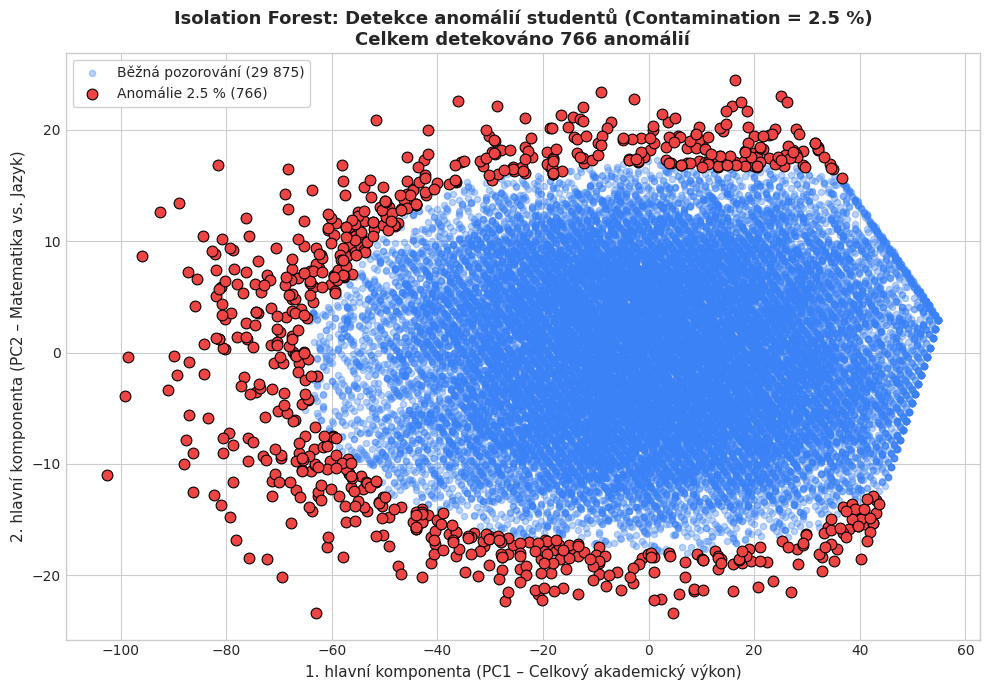

In [5]:
# Vizualizace Modelu A (2.5 %)
plt.figure(figsize=(10, 7))
plt.scatter(scores_df.loc[~scores_df['is_outlier_025'], 'pca_1'],
            scores_df.loc[~scores_df['is_outlier_025'], 'pca_2'],
            c='#3b82f6', label='Běžná pozorování (29 875)', alpha=0.35, s=20)
plt.scatter(scores_df.loc[scores_df['is_outlier_025'], 'pca_1'],
            scores_df.loc[scores_df['is_outlier_025'], 'pca_2'],
            c='#ef4444', label=f'Anomálie 2.5 % ({n_outliers_025})', s=60, edgecolors='black', linewidth=0.8, zorder=5)
plt.title(f'Isolation Forest: Detekce anomálií studentů (Contamination = 2.5 %)\nCelkem detekováno {n_outliers_025} anomálií', fontsize=13, fontweight='bold')
plt.xlabel('1. hlavní komponenta (PC1 – Celkový akademický výkon)', fontsize=11)
plt.ylabel('2. hlavní komponenta (PC2 – Matematika vs. Jazyk)', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

## 4. Model B: Isolation Forest s kontaminací 1.0 %

Nyní zúžíme filtr na nejpřísnější kritérium: předpokládáme podíl anomálií pouze 1.0 % (`contamination=0.01`).

In [6]:
# Trénování modelu B (1.0 %)
iso_01 = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42
)

y_pred_01 = iso_01.fit_predict(X_pca)
scores_df['is_outlier_01'] = (y_pred_01 == -1)
scores_df['score_01'] = iso_01.decision_function(X_pca)

n_outliers_01 = (y_pred_01 == -1).sum()
print(f'Počet anomálií při 1.0 % kontaminaci: {n_outliers_01} z {len(scores_df)} ({n_outliers_01/len(scores_df)*100:.2f} %)')
print(f'Rozhodovací offset: {iso_01.offset_:.4f}')

Počet anomálií při 1.0 % kontaminaci: 307 z 30641 (1.00 %)
Rozhodovací offset: -0.6403


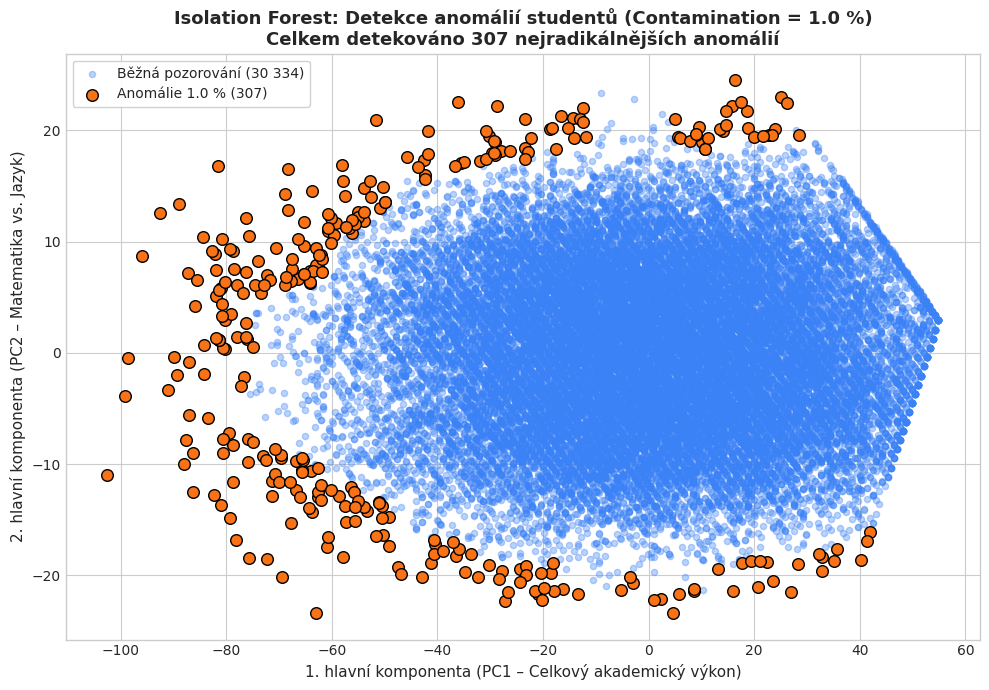

In [7]:
# Vizualizace Modelu B (1.0 %)
plt.figure(figsize=(10, 7))
plt.scatter(scores_df.loc[~scores_df['is_outlier_01'], 'pca_1'],
            scores_df.loc[~scores_df['is_outlier_01'], 'pca_2'],
            c='#3b82f6', label='Běžná pozorování (30 334)', alpha=0.35, s=20)
plt.scatter(scores_df.loc[scores_df['is_outlier_01'], 'pca_1'],
            scores_df.loc[scores_df['is_outlier_01'], 'pca_2'],
            c='#f97316', label=f'Anomálie 1.0 % ({n_outliers_01})', s=70, edgecolors='black', linewidth=1.0, zorder=5)
plt.title(f'Isolation Forest: Detekce anomálií studentů (Contamination = 1.0 %)\nCelkem detekováno {n_outliers_01} nejradikálnějších anomálií', fontsize=13, fontweight='bold')
plt.xlabel('1. hlavní komponenta (PC1 – Celkový akademický výkon)', fontsize=11)
plt.ylabel('2. hlavní komponenta (PC2 – Matematika vs. Jazyk)', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

## 5. Srovnání změn v grafu: Jak se projevilo snížení kontaminace z 2.5 % na 1.0 %?

Při snížení kontaminace z 2.5 % na 1.0 %:
- Počet anomálií klesl ze **766** na **307** (-459 studentů, pokles o 60 %).
- Všech 307 případů z 1.0% modelu tvoří **podmnožinu** anomálií z 2.5% modelu.
- Těchto 459 odebraných studentů tvoří mírnější přechodovou zónu na obvodu rozdělení.

In [8]:
# Klasifikace přechodových kategorií
def get_transition_cat(row):
    if row['is_outlier_01']:
        return 'Extrémní anomálie (1.0 % i 2.5 %)'
    elif row['is_outlier_025']:
        return 'Mírnější anomálie (pouze při 2.5 %)'
    else:
        return 'Běžný student (Inlier)'

scores_df['transition_cat'] = scores_df.apply(get_transition_cat, axis=1)
print('Počty studentů v kategoriích:')
print(scores_df['transition_cat'].value_counts())

Počty studentů v kategoriích:
transition_cat
Běžný student (Inlier)                 29875
Mírnější anomálie (pouze při 2.5 %)      459
Extrémní anomálie (1.0 % i 2.5 %)        307
Name: count, dtype: int64


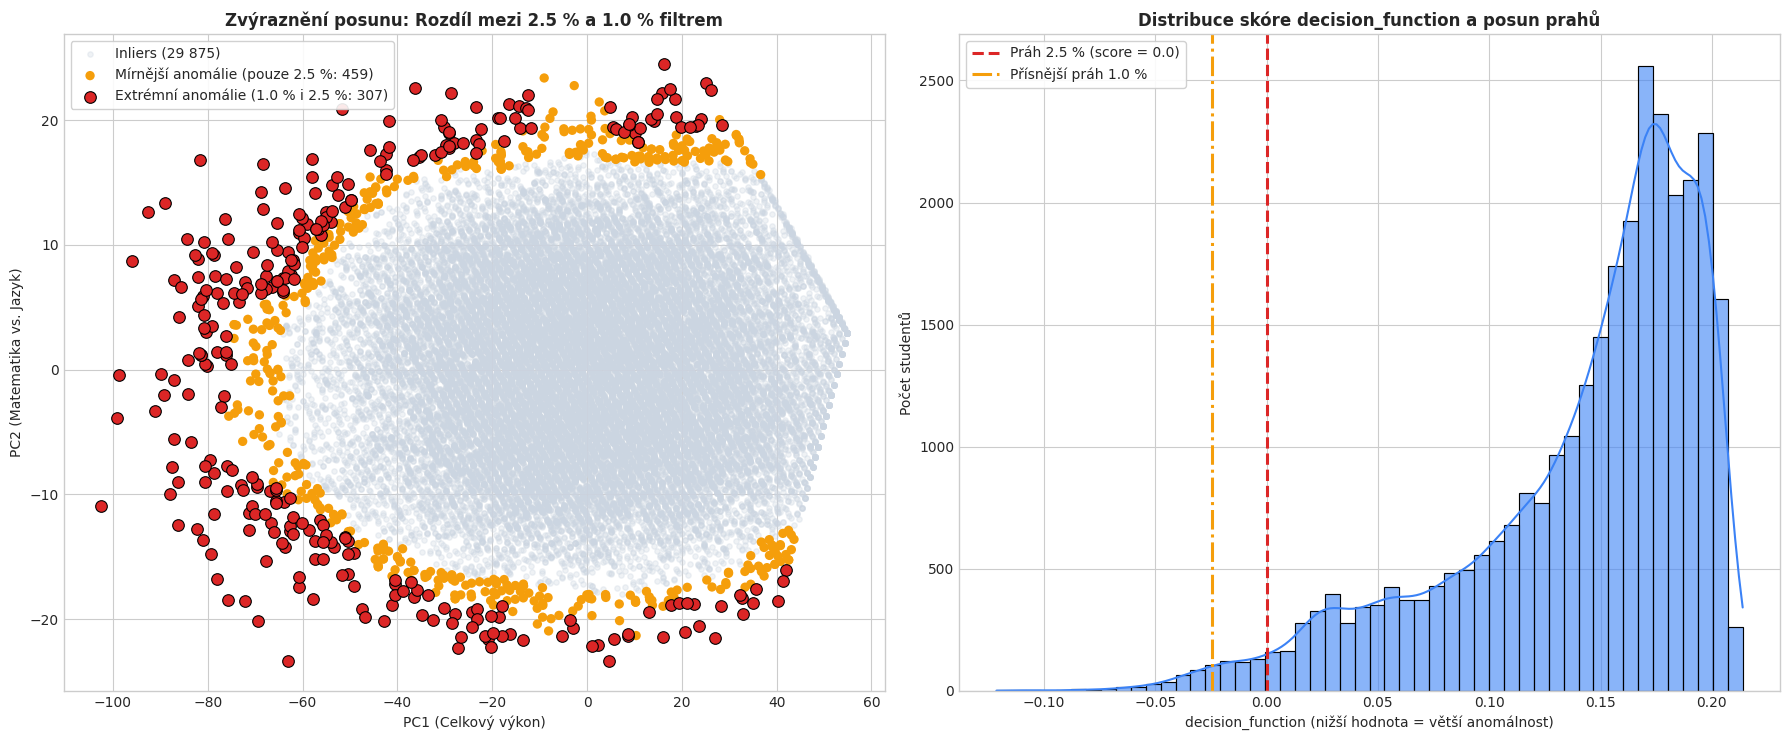

In [9]:
# Přímé srovnání: Zvýraznění posunu hranice
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

# Levý graf: Kategorizované body
axes[0].scatter(scores_df.loc[scores_df['transition_cat'] == 'Běžný student (Inlier)', 'pca_1'],
                scores_df.loc[scores_df['transition_cat'] == 'Běžný student (Inlier)', 'pca_2'],
                c='#cbd5e1', alpha=0.3, s=15, label='Inliers (29 875)')
axes[0].scatter(scores_df.loc[scores_df['transition_cat'] == 'Mírnější anomálie (pouze při 2.5 %)', 'pca_1'],
                scores_df.loc[scores_df['transition_cat'] == 'Mírnější anomálie (pouze při 2.5 %)', 'pca_2'],
                c='#f59e0b', s=45, edgecolors='none', label='Mírnější anomálie (pouze 2.5 %: 459)')
axes[0].scatter(scores_df.loc[scores_df['transition_cat'] == 'Extrémní anomálie (1.0 % i 2.5 %)', 'pca_1'],
                scores_df.loc[scores_df['transition_cat'] == 'Extrémní anomálie (1.0 % i 2.5 %)', 'pca_2'],
                c='#dc2626', s=70, edgecolors='black', linewidth=0.8, label='Extrémní anomálie (1.0 % i 2.5 %: 307)')
axes[0].set_title('Zvýraznění posunu: Rozdíl mezi 2.5 % a 1.0 % filtrem', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PC1 (Celkový výkon)')
axes[0].set_ylabel('PC2 (Matematika vs. Jazyk)')
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Pravý graf: Distribuce rozhodovací funkce a prahy
sns.histplot(scores_df['score_025'], bins=50, ax=axes[1], color='#3b82f6', alpha=0.6, kde=True)
axes[1].axvline(0.0, color='#dc2626', linestyle='--', linewidth=2.2, label='Práh 2.5 % (score = 0.0)')
axes[1].axvline(iso_01.offset_ - iso_025.offset_, color='#f59e0b', linestyle='-.', linewidth=2.2, label=f'Přísnější práh 1.0 %')
axes[1].set_title('Distribuce skóre decision_function a posun prahů', fontsize=12, fontweight='bold')
axes[1].set_xlabel('decision_function (nižší hodnota = větší anomálnost)')
axes[1].set_ylabel('Počet studentů')
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

## 6. Detailní pohled na profily anomálních studentů

Podívejme se na konkrétní známky studentů, které model označil za nejextrémnější anomálie:

In [10]:
# Top 10 nejvýraznějších anomálií podle nejnižšího skóre rozhodovací funkce
top_outliers = scores_df[scores_df['is_outlier_01']].sort_values(by='score_01', ascending=True).head(15)
print('Ukázka 15 nejextrémnějších anomálií v datasetu:')
display(top_outliers[['MathScore', 'ReadingScore', 'WritingScore', 'pca_1', 'pca_2', 'score_01']].round(2))

Ukázka 15 nejextrémnějších anomálií v datasetu:


,MathScore,ReadingScore,WritingScore,pca_1,pca_2,score_01
30105,11,39,34,-69.43,-20.16,-0.10
25251,35,13,16,-81.60,16.80,-0.09
30161,9,32,32,-75.76,-18.44,-0.09
15058,11,32,36,-72.25,-18.53,-0.09
29696,9,31,29,-78.12,-16.78,-0.08
9257,12,43,40,-62.99,-23.37,-0.08
29283,42,24,21,-68.38,16.48,-0.08
22147,10,29,28,-79.30,-14.80,-0.08
22015,10,27,27,-81.05,-13.65,-0.07
28704,28,10,13,-89.04,13.39,-0.07


## 7. Závěry cvičení

1. **PCA 2D projekce:** 1. komponenta (90.6 % rozptylu) zachycuje celkový souhrnný výkon, zatímco 2. komponenta (7.9 % rozptylu) vyjadřuje nepoměr mezi matematikou a jazykem. Společně vysvětlují **98.5 % rozptylu**.
2. **Charakter odhalených anomálií:** Isolation Forest odhalil dva základní typy extrémů:
   - Studenty s extrémně nízkým výkonem ve všech třech testech (např. body 0–25).
   - Studenty s masivní disproporcí (např. vynikající matematika 95, ale kolaps v jazyce 20–30, nebo naopak).
3. **Vliv parametru kontaminace:**
   - Při `contamination=0.025` je označeno **766 studentů** (zahrnuje i mírnější disbalance).
   - Při `contamination=0.01` se filtr zúží na **307 studentů** (pouze fatální selhání a extrémní kontrasty).
   - Snížením kontaminace klesá počet falešných poplachů a zvyšuje se věcná závažnost zachycených případů.